In [1]:
import pandas as pd
dataset=pd.read_csv("Tatacoffee13_21.csv", parse_dates=['Date'], index_col='Date')

In [2]:
dataset

,Open,High,Low,Close
Date,,,,
2013-01-01,1410.60,1427.90,1408.30,1415.10
2013-01-02,1421.00,1626.60,1416.15,1607.40
2013-01-03,1632.55,1673.90,1613.05,1626.20
2013-01-04,1627.75,1627.75,1574.60,1579.05
2013-01-07,1580.00,1639.50,1565.50,1595.65
...,...,...,...,...
2021-12-22,202.90,207.80,201.35,205.00
2021-12-23,206.00,206.85,202.05,202.95
2021-12-24,203.90,203.90,199.35,201.00


In [3]:
#Start date and end_date
from datetime import date, timedelta
import pandas as pd
start_date = pd.to_datetime("2013-01-01")
end_date = pd.to_datetime("2019-02-04") - timedelta(days=1) #Excluding last

#List of all dates
all_date = pd.date_range(start_date, end_date, freq='d')

In [4]:
all_date

DatetimeIndex(['2013-01-01', '2013-01-02', '2013-01-03', '2013-01-04',
               '2013-01-05', '2013-01-06', '2013-01-07', '2013-01-08',
               '2013-01-09', '2013-01-10',
               ...
               '2019-01-25', '2019-01-26', '2019-01-27', '2019-01-28',
               '2019-01-29', '2019-01-30', '2019-01-31', '2019-02-01',
               '2019-02-02', '2019-02-03'],
              dtype='datetime64[ns]', length=2225, freq='D')

In [5]:
dummyDate=dataset

In [6]:
dummyDate.index=all_date

In [7]:
dummyDate

,Open,High,Low,Close
2013-01-01,1410.60,1427.90,1408.30,1415.10
2013-01-02,1421.00,1626.60,1416.15,1607.40
2013-01-03,1632.55,1673.90,1613.05,1626.20
2013-01-04,1627.75,1627.75,1574.60,1579.05
2013-01-05,1580.00,1639.50,1565.50,1595.65
...,...,...,...,...
2019-01-30,202.90,207.80,201.35,205.00
2019-01-31,206.00,206.85,202.05,202.95
2019-02-01,203.90,203.90,199.35,201.00
2019-02-02,200.00,222.00,196.00,218.35


In [8]:
#DateIndex.index=pd.to_datetime(dataset["Date"],infer_datetime_format=True)

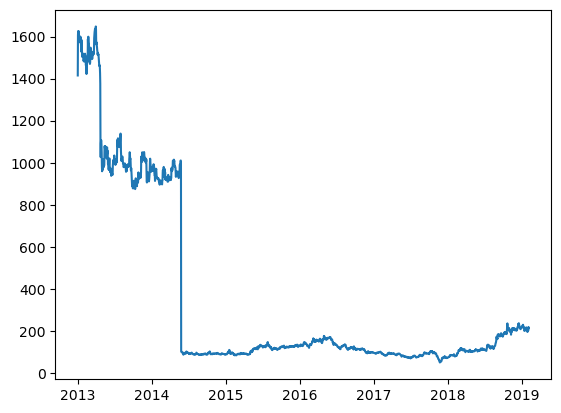

In [9]:
import matplotlib.pyplot as plt
plt.plot(dataset["Close"])

<Figure size 1600x500 with 0 Axes>

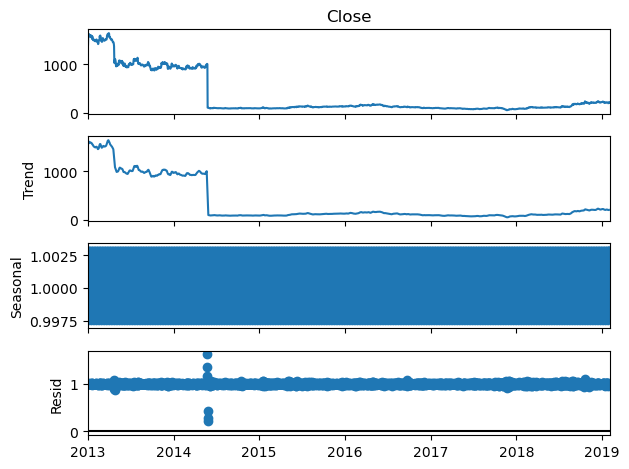

In [10]:
from pandas import read_csv
from matplotlib import pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
result = seasonal_decompose(dummyDate["Close"], model='multiplicative')
plt.figure(figsize=(16,5))
result.plot()
plt.show()

<Figure size 1600x500 with 0 Axes>

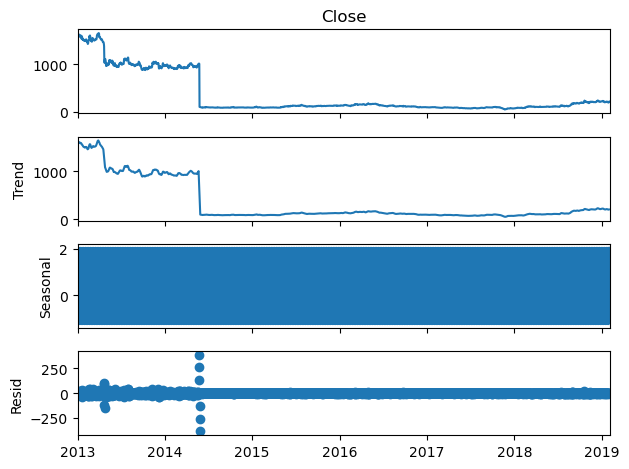

In [11]:
from pandas import read_csv
from matplotlib import pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
result = seasonal_decompose(dummyDate["Close"], model='additive')
plt.figure(figsize=(16,5))
result.plot()
plt.show()

In [34]:

# ADF Test
# Function to print out results in customised manner
from statsmodels.tsa.stattools import adfuller
def adf_test(timeseries,df,pollutant):
    plt.figure(figsize=(16,5))
    # Plot the data
    # ADF Test
    # Function to print out results in customised manner
    from statsmodels.tsa.stattools import adfuller
    print ('Results of Dickey-Fuller Test:')
    dftest = adfuller(timeseries, autolag='AIC')
    #Assignment ---printed dftest-The adfuller() function from statsmodels.tsa.stattools returns a tuple (dftest) containing 6 elements returned by statsmodels.tsa.stattools.adfuller:'0-Test Statistic','1-p-value','2-#Lags Used','3-Number of Observations Used','4-Dictionary of critical thresholds','5-Maximized Information'
    print(dftest)
    dfoutput = pd.Series(dftest[0:5], index=['Test Statistic','p-value','#Lags Used','Number of Observations Used','Dictionary of critical thresholds'])
    
    for key,value in dftest[4].items():
        dfoutput['Critical Value (%s)'%key] = value
    print (dfoutput)
    ans=dfoutput
    print("Condition:")
    print("p-value<=0.05-->Accept Alternate Hypothesis")
    print("p-value>0.05-->Accept Null Hypothesis")
    if(ans['Test Statistic']<ans["Critical Value (1%)"] or ans['Test Statistic']<ans["Critical Value (5%)"] or ans['Test Statistic']<ans["Critical Value (10%)"] and ans["p-value"]<0.05):
        print("Condition: statictic < any critical value and p-value <0.05 to reject null hypothsis")
        print("Reject null hypothesis:Non Stationarity")
        print("Accept Alternate hypothesis:Staionarity ")
        message="Stationarity based on ADH"
    else:
        print("Condition: statictic < any critical value and p-value <0.05 to reject null hypothsis")
        print("Accept null hypothesis:Non Stationarity" )
        print("Reject Alternate hypothesis:Staionarity ")
        message="Non-stationarity based on ADH"
        
    plt.plot(df.index, df[pollutant], label = pollutant)
    plt.legend(loc='best')
    plt.title("{}_{}_2013 to 2021".format(message,pollutant))
    plt.savefig("{}_ADH.png".format(pollutant))
    plt.show()
    
    return message
    
# Call the function and run the test



Results of Dickey-Fuller Test:
(np.float64(-3.007236327367319), np.float64(0.0342241222909299), 1, 2223, {'1%': np.float64(-3.433295059438173), '5%': np.float64(-2.8628410403669844), '10%': np.float64(-2.5674626062113077)}, np.float64(19813.538287196585))
Test Statistic                                                               -3.007236
p-value                                                                       0.034224
#Lags Used                                                                           1
Number of Observations Used                                                       2223
Dictionary of critical thresholds    {'1%': -3.433295059438173, '5%': -2.8628410403...
Critical Value (1%)                                                          -3.433295
Critical Value (5%)                                                          -2.862841
Critical Value (10%)                                                         -2.567463
dtype: object
Condition:
p-value<=0.05-->Accept 

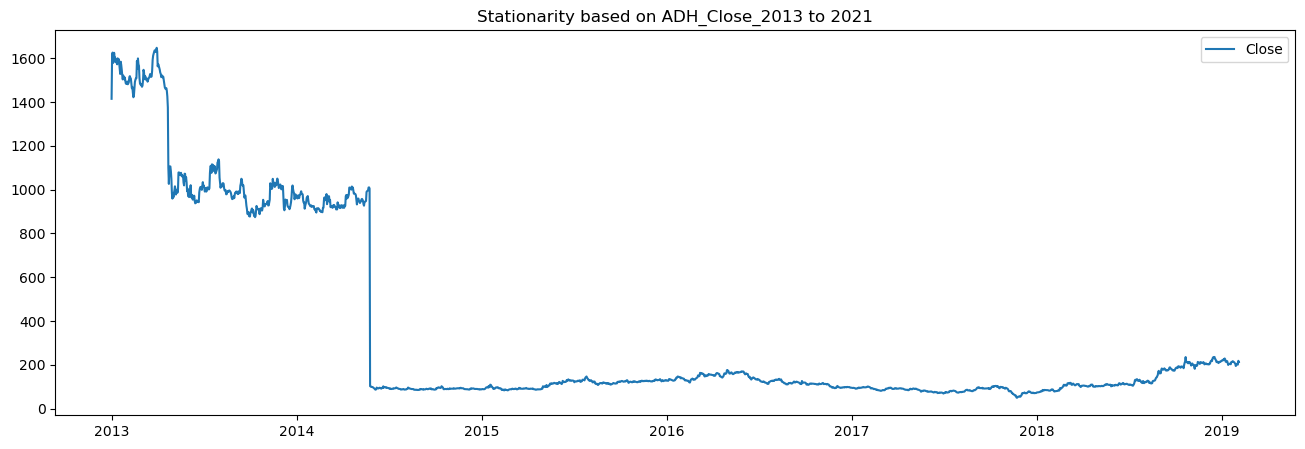

'Stationarity based on ADH'

In [35]:
adf_test(dataset["Close"],dataset,"Close")

=== Results of Dickey-Fuller Test ===

Raw adfuller output tuple (dftest):
(np.float64(-3.007236327367319), np.float64(0.0342241222909299), 1, 2223, {'1%': np.float64(-3.433295059438173), '5%': np.float64(-2.8628410403669844), '10%': np.float64(-2.5674626062113077)}, np.float64(19813.538287196585))

Formatted ADF Output Series (dfoutput):
Test Statistic                                                         -3.007236
p-value                                                                 0.034224
#Lags Used                                                                     1
Number of Observations Used                                                 2223
Critical value(dictionary)     {'1%': -3.433295059438173, '5%': -2.8628410403...
Critical Value (1%)                                                    -3.433295
Critical Value (5%)                                                    -2.862841
Critical Value (10%)                                                   -2.567463
dtype: obje

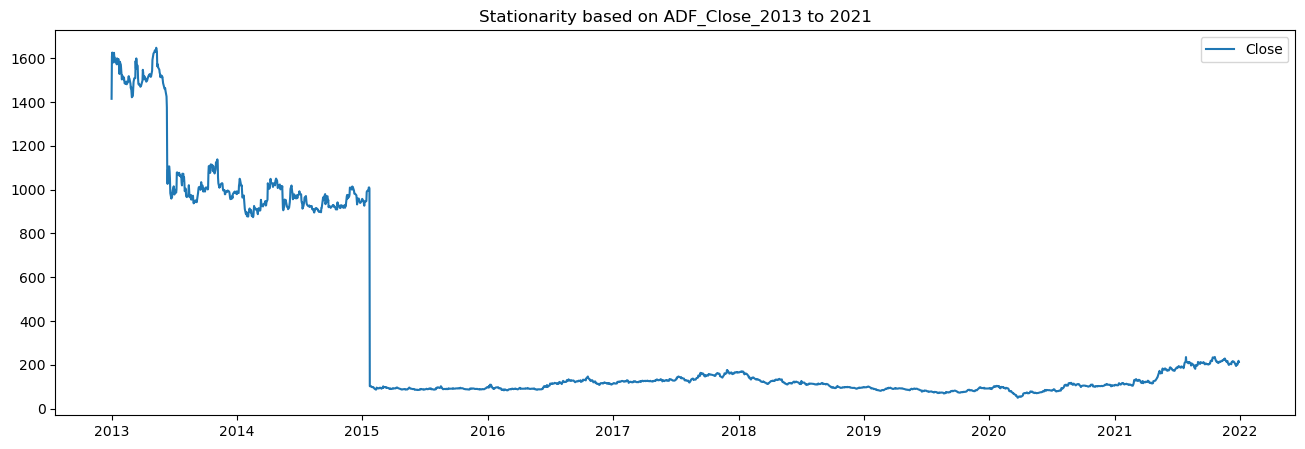


Final Result Message: Stationarity based on ADF


In [48]:
#Assignment -Rewrite the code without writing a function.
# Load the dataset
df=pd.read_csv("Tatacoffee13_21.csv", parse_dates=['Date'], index_col='Date')

# Drop missing values from the target column to prevent adfuller from throwing an error
timeseries = df['Close'].dropna()
print('=== Results of Dickey-Fuller Test ===')
dftest = adfuller(timeseries, autolag='AIC')

# Print the raw tuple returned by adfuller
print("\nRaw adfuller output tuple (dftest):")
print(dftest)


# ---------------------------------------------------------
# 3. FORMAT OUTPUT INTO PANDAS SERIES
# ---------------------------------------------------------
# Note: Slice index 0:5 for scalar values; element 4 is the dictionary of critical values
dfoutput = pd.Series(
    dftest[0:5], 
    index=['Test Statistic', 'p-value', '#Lags Used', 'Number of Observations Used','Critical value(dictionary)']
)

# Unpack the dictionary of critical values into the series
for key, value in dftest[4].items():
    dfoutput['Critical Value (%s)' % key] = value

print("\nFormatted ADF Output Series (dfoutput):")
print(dfoutput)


# ---------------------------------------------------------
# 4. STATISTICAL DECISION LOGIC
# ---------------------------------------------------------
ans = dfoutput

print("\nCondition Rules:")
print("p-value <= 0.05 --> Reject Null Hypothesis (Stationary)")
print("p-value > 0.05  --> Fail to Reject Null Hypothesis (Non-Stationary)")

# Standard statistical check (p-value threshold)
if ans["p-value"] <= 0.05:
    print("\nCondition: p-value <= 0.05")
    print("Reject null hypothesis: Non-Stationarity")
    print("Accept alternate hypothesis: Stationarity")
    message = "Stationarity based on ADF"
else:
    print("\nCondition: p-value > 0.05")
    print("Accept null hypothesis: Non-Stationarity")
    print("Reject alternate hypothesis: Stationarity")
    message = "Non-stationarity based on ADF"


# ---------------------------------------------------------
# 5. DATA VISUALIZATION & PLOT SAVING
# ---------------------------------------------------------
plt.figure(figsize=(16, 5))
plt.plot(df.index, df['Close'], label='Close')
plt.legend(loc='best')
plt.title(f"{message}_{'Close'}_2013 to 2021")
plt.savefig(f"{'Close'}_ADF.png")
plt.show()

print(f"\nFinal Result Message: {message}")

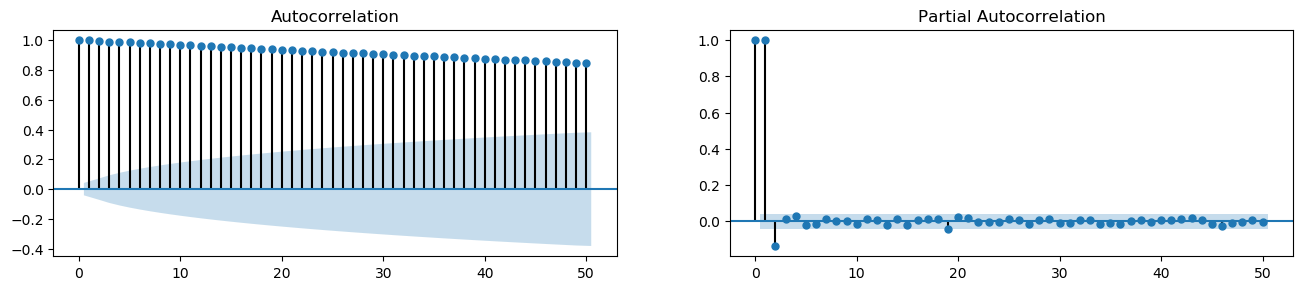

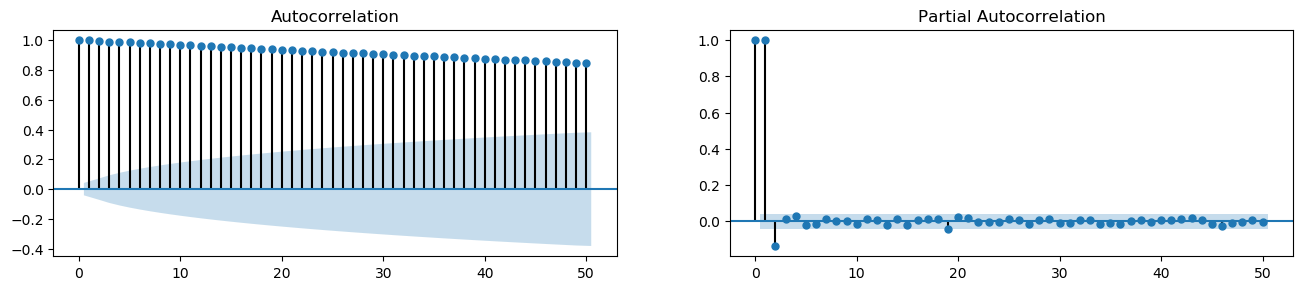

In [76]:
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1,2,figsize=(16,3), dpi= 100)
plot_acf(dataset.Close.tolist(), lags=50, ax=axes[0])
plot_pacf(dataset.Close.tolist(), lags=50, ax=axes[1])

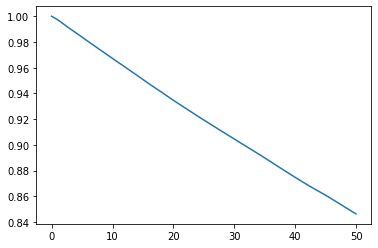

In [84]:
plt.plot(acf(dataset["Close"],nlags=50))

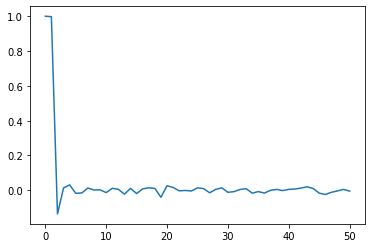

In [87]:
plt.plot(pacf(dataset["Close"],nlags=50))

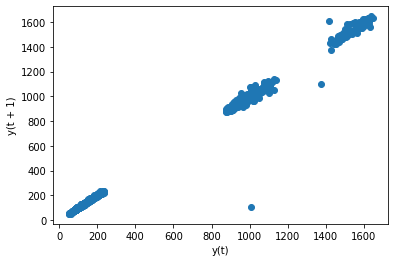

In [93]:
from pandas.plotting import lag_plot
lag_plot(dataset["Close"],lag=1)

## Forecastability

### Apen small- Forecastability is possible
### Spen Small-Forecastability is possible

In [94]:
def ApEn(U, m, r):
    """Compute Aproximate entropy"""
    def _maxdist(x_i, x_j):
        return max([abs(ua - va) for ua, va in zip(x_i, x_j)])

    def _phi(m):
        x = [[U[j] for j in range(i, i + m - 1 + 1)] for i in range(N - m + 1)]
        C = [len([1 for x_j in x if _maxdist(x_i, x_j) <= r]) / (N - m + 1.0) for x_i in x]
        return (N - m + 1.0)**(-1) * sum(np.log(C))

    N = len(U)
    return abs(_phi(m+1) - _phi(m))

In [97]:
import numpy as np
print(ApEn(dataset["Close"], m=2, r=0.2*np.std(dataset["Close"])))  

0.027409184525792107


In [98]:
def SampEn(U, m, r):
    """Compute Sample entropy"""
    def _maxdist(x_i, x_j):
        return max([abs(ua - va) for ua, va in zip(x_i, x_j)])

    def _phi(m):
        x = [[U[j] for j in range(i, i + m - 1 + 1)] for i in range(N - m + 1)]
        C = [len([1 for j in range(len(x)) if i != j and _maxdist(x[i], x[j]) <= r]) for i in range(len(x))]
        return sum(C)

    N = len(U)
    return -np.log(_phi(m+1) / _phi(m))

In [99]:
print(SampEn(dataset["Close"], m=2, r=0.2*np.std(dataset["Close"])))

0.007918086989927514
